In [2]:
#montar drive
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from scipy.stats import spearmanr, pearsonr
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score, silhouette_score, davies_bouldin_score
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=RuntimeWarning)

RANDOM_STATE = 42
N_SPLITS = 5
N_ESTIMATORS = 500
MAX_DEPTH = 8
SELECTED_K = 3

DATA_PATH = Path("/content/drive/MyDrive/Doctorado/Traces/tpcds_complexity_dataset.csv")
RESULTS_DIR = Path("results")
FIGURES_DIR = Path("figures")
ARTIFACTS_DIR = Path("artifacts")

for directory in (RESULTS_DIR, FIGURES_DIR, ARTIFACTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

Mounted at /content/drive


## 1. Load and normalize column names

In [3]:
df = pd.read_csv(DATA_PATH)

# Accept common aliases without changing the scientific definitions.
COLUMN_ALIASES = {
    "query": "template_id",
    "query_name": "template_id",
    "scale_factor_tb": "scale_factor",
    "emr_observed": "executed_emr",
    "runtime_seconds": "runtime_observed",
    "allocated_workers": "worker_nodes",
}

for old_name, new_name in COLUMN_ALIASES.items():
    if old_name in df.columns and new_name not in df.columns:
        df = df.rename(columns={old_name: new_name})

required_columns = {
    "template_id", "scale_factor",
    "join_count", "group_by_count", "distinct_count", "window_count",
    "subquery_count", "cte_real_subqueries_count",
    "subquery_chain_depth_main", "table_count", "join_to_table_ratio",
    "repeated_bytes_ratio", "table_size_cv",
    "executed_emr", "runtime_observed", "worker_nodes",
}

missing = required_columns - set(df.columns)
if missing:
    raise ValueError(f"Missing required columns: {sorted(missing)}")

# Normalize the EMR flag robustly.
if df["executed_emr"].dtype != bool:
    df["executed_emr"] = (
        df["executed_emr"].astype(str).str.strip().str.lower()
        .map({"true": True, "1": True, "yes": True,
              "false": False, "0": False, "no": False})
    )

numeric_columns = [
    "scale_factor", "runtime_observed", "worker_nodes",
    "join_count", "group_by_count", "distinct_count", "window_count",
    "subquery_count", "cte_real_subqueries_count",
    "subquery_chain_depth_main", "table_count", "join_to_table_ratio",
    "repeated_bytes_ratio", "table_size_cv",
]
for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

print("Unified dataset shape:", df.shape)
print("Unique templates:", df["template_id"].nunique())
print("Scale factors:", sorted(df["scale_factor"].dropna().unique()))
print("Rows with observed EMR runtime:", df["runtime_observed"].notna().sum())

Unified dataset shape: (357, 24)
Unique templates: 99
Scale factors: [np.int64(1), np.int64(3), np.int64(10)]
Rows with observed EMR runtime: 72


## 2. Define the exact feature families used in the paper

In [4]:
FEATURES_TRADITIONAL = [
    "join_count",
    "group_by_count",
    "distinct_count",
    "window_count",
]

FEATURES_SEMANTIC = [
    "subquery_count",
    "cte_real_subqueries_count",
    "subquery_chain_depth_main",
    "table_count",
    "join_to_table_ratio",
]

FEATURES_REUSE_VOLUME = [
    "repeated_bytes_ratio",
    "table_size_cv",
]

FEATURES_HYBRID = (
    FEATURES_TRADITIONAL
    + FEATURES_SEMANTIC
    + FEATURES_REUSE_VOLUME
)

SURROGATE_FEATURES = FEATURES_SEMANTIC + FEATURES_REUSE_VOLUME

assert len(FEATURES_TRADITIONAL) == 4
assert len(FEATURES_SEMANTIC) == 5
assert len(FEATURES_REUSE_VOLUME) == 2
assert len(FEATURES_HYBRID) == 11
assert len(SURROGATE_FEATURES) == 7
assert len(set(FEATURES_HYBRID)) == 11

print("Traditional:", FEATURES_TRADITIONAL)
print("Semantic:", FEATURES_SEMANTIC)
print("Reuse/volume:", FEATURES_REUSE_VOLUME)
print("Hybrid feature count:", len(FEATURES_HYBRID))

Traditional: ['join_count', 'group_by_count', 'distinct_count', 'window_count']
Semantic: ['subquery_count', 'cte_real_subqueries_count', 'subquery_chain_depth_main', 'table_count', 'join_to_table_ratio']
Reuse/volume: ['repeated_bytes_ratio', 'table_size_cv']
Hybrid feature count: 11


## 3. Separate the 297 characterization observations from repeated EMR executions

In [5]:
# Every characterization experiment must contain one row per template and scale factor.
key_columns = ["template_id", "scale_factor"]

# Ensure repeated rows have identical SQL descriptors before deduplication.
variation = df.groupby(key_columns)[FEATURES_HYBRID].nunique(dropna=False)
problem_keys = variation[(variation > 1).any(axis=1)]
if not problem_keys.empty:
    raise ValueError(
        "Repeated EMR rows contain inconsistent query descriptors for these keys:"
        f"{problem_keys}"
    )

characterization_df = (
    df.sort_values(key_columns)
      .drop_duplicates(subset=key_columns, keep="first")
      .copy()
)

runtime_df = df[
    df["executed_emr"].eq(True)
    & df["runtime_observed"].notna()
    & df["worker_nodes"].notna()
].copy()

print("Characterization rows:", characterization_df.shape[0])
print("Characterization templates:", characterization_df["template_id"].nunique())
print("Runtime rows:", runtime_df.shape[0])
print("Runtime templates:", runtime_df["template_id"].nunique())

assert characterization_df.shape[0] == 297, "Expected exactly 297 unique template-scale observations."
assert characterization_df["template_id"].nunique() == 99, "Expected 99 query templates."
assert set(characterization_df["scale_factor"].unique()) == {1, 3, 10}, "Expected 1, 3, and 10 TB."
assert runtime_df.shape[0] == 72, "Expected exactly 72 observed EMR executions."
assert runtime_df["template_id"].nunique() == 6, "Expected six executed query templates."

if characterization_df[FEATURES_HYBRID].isna().any().any():
    raise ValueError("Missing values found in characterization features.")

Characterization rows: 297
Characterization templates: 99
Runtime rows: 72
Runtime templates: 6


## 4. Construct and freeze the PCA-based latent characterization target

In [6]:
pca_scaler = StandardScaler()
Z = pca_scaler.fit_transform(characterization_df[SURROGATE_FEATURES])

pca_full = PCA().fit(Z)
pca_target = PCA(n_components=1).fit(Z)

characterization_df["complexity_surrogate"] = pca_target.transform(Z).ravel()

explained_variance = pca_full.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

pca_variance_df = pd.DataFrame({
    "Component": [f"PC{i+1}" for i in range(len(explained_variance))],
    "Explained_Variance": explained_variance,
    "Cumulative_Variance": cumulative_variance,
})

loadings_df = pd.DataFrame({
    "Feature": SURROGATE_FEATURES,
    "PC1_Loading": pca_target.components_[0],
})
loadings_df["Abs_PC1_Loading"] = loadings_df["PC1_Loading"].abs()
loadings_df = loadings_df.sort_values("Abs_PC1_Loading", ascending=False)

print(pca_variance_df)
print("PC1 loadings:")
print(loadings_df)

pca_variance_df.to_csv(RESULTS_DIR / "pca_explained_variance.csv", index=False)
loadings_df.to_csv(RESULTS_DIR / "pca_pc1_loadings.csv", index=False)
np.save(ARTIFACTS_DIR / "pca_scaler_mean.npy", pca_scaler.mean_)
np.save(ARTIFACTS_DIR / "pca_scaler_scale.npy", pca_scaler.scale_)
np.save(ARTIFACTS_DIR / "pca_pc1_components.npy", pca_target.components_)

  Component  Explained_Variance  Cumulative_Variance
0       PC1            0.393451             0.393451
1       PC2            0.214772             0.608223
2       PC3            0.145816             0.754039
3       PC4            0.126913             0.880952
4       PC5            0.067518             0.948470
5       PC6            0.036325             0.984795
6       PC7            0.015205             1.000000
PC1 loadings:
                     Feature  PC1_Loading  Abs_PC1_Loading
0             subquery_count     0.515217         0.515217
1  cte_real_subqueries_count     0.502901         0.502901
2  subquery_chain_depth_main     0.466192         0.466192
3                table_count     0.383839         0.383839
6              table_size_cv    -0.247751         0.247751
5       repeated_bytes_ratio     0.196989         0.196989
4        join_to_table_ratio     0.129575         0.129575


## 5. Grouped comparative evaluation

In [7]:
def safe_spearman(y_true, y_pred):
    rho, _ = spearmanr(y_true, y_pred)
    return float(rho) if np.isfinite(rho) else np.nan


def evaluate_grouped_model(data, features, target="complexity_surrogate"):
    X = data[features]
    y = data[target]
    groups = data["template_id"]
    splitter = GroupKFold(n_splits=N_SPLITS)

    fold_rows = []
    for fold, (train_idx, test_idx) in enumerate(
        splitter.split(X, y, groups=groups), start=1
    ):
        model = RandomForestRegressor(
            n_estimators=N_ESTIMATORS,
            max_depth=MAX_DEPTH,
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )
        model.fit(X.iloc[train_idx], y.iloc[train_idx])
        predictions = model.predict(X.iloc[test_idx])

        fold_rows.append({
            "Fold": fold,
            "R2": r2_score(y.iloc[test_idx], predictions),
            "Spearman": safe_spearman(y.iloc[test_idx], predictions),
            "Train_Rows": len(train_idx),
            "Test_Rows": len(test_idx),
            "Test_Templates": data.iloc[test_idx]["template_id"].nunique(),
        })

    folds = pd.DataFrame(fold_rows)
    summary = {
        "Mean_R2": folds["R2"].mean(),
        "Std_R2": folds["R2"].std(ddof=0),
        "Mean_Spearman": folds["Spearman"].mean(),
        "Std_Spearman": folds["Spearman"].std(ddof=0),
    }
    return summary, folds

MODEL_FEATURES = {
    "Traditional": FEATURES_TRADITIONAL,
    "Semantic": FEATURES_SEMANTIC,
    "Hybrid": FEATURES_HYBRID,
}

comparison_rows = []
all_comparison_folds = []

for model_name, features in MODEL_FEATURES.items():
    summary, folds = evaluate_grouped_model(characterization_df, features)
    comparison_rows.append({"Model": model_name, **summary})
    folds.insert(0, "Model", model_name)
    all_comparison_folds.append(folds)

comparison_df = pd.DataFrame(comparison_rows)
comparison_folds_df = pd.concat(all_comparison_folds, ignore_index=True)

print(comparison_df)
comparison_df.to_csv(RESULTS_DIR / "table_ii_model_comparison.csv", index=False)
comparison_folds_df.to_csv(RESULTS_DIR / "model_comparison_by_fold.csv", index=False)

         Model   Mean_R2    Std_R2  Mean_Spearman  Std_Spearman
0  Traditional  0.430537  0.158129       0.545297      0.133519
1     Semantic  0.915370  0.017419       0.928399      0.037520
2       Hybrid  0.920290  0.027457       0.976042      0.005961


## 6. Descriptive feature attribution

In [8]:
X_hybrid = characterization_df[FEATURES_HYBRID]
y_target = characterization_df["complexity_surrogate"]

hybrid_model = RandomForestRegressor(
    n_estimators=N_ESTIMATORS,
    max_depth=MAX_DEPTH,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
hybrid_model.fit(X_hybrid, y_target)

explainer = shap.TreeExplainer(hybrid_model)
shap_values = explainer.shap_values(X_hybrid)

mean_abs_shap = np.abs(shap_values).mean(axis=0)
shap_ranking_df = pd.DataFrame({
    "Feature": FEATURES_HYBRID,
    "Mean_Abs_SHAP": mean_abs_shap,
}).sort_values("Mean_Abs_SHAP", ascending=False)

shap_ranking_df.to_csv(RESULTS_DIR / "shap_ranking.csv", index=False)

shap.summary_plot(shap_values, X_hybrid, show=False, max_display=11)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "shap_summary.png", dpi=300, bbox_inches="tight")
plt.close()

permutation = permutation_importance(
    hybrid_model,
    X_hybrid,
    y_target,
    n_repeats=30,
    random_state=RANDOM_STATE,
    scoring="r2",
    n_jobs=-1,
)

permutation_df = pd.DataFrame({
    "Feature": FEATURES_HYBRID,
    "Importance": permutation.importances_mean,
    "Std": permutation.importances_std,
}).sort_values("Importance", ascending=False)

print("SHAP ranking:")
print(shap_ranking_df)
print("Permutation importance:")
print(permutation_df)

permutation_df.to_csv(RESULTS_DIR / "table_iii_permutation_importance.csv", index=False)

SHAP ranking:
                      Feature  Mean_Abs_SHAP
5   cte_real_subqueries_count       0.826914
4              subquery_count       0.350925
6   subquery_chain_depth_main       0.167405
10              table_size_cv       0.148893
7                 table_count       0.100481
9        repeated_bytes_ratio       0.074553
1              group_by_count       0.034044
0                  join_count       0.011815
8         join_to_table_ratio       0.010667
2              distinct_count       0.007220
3                window_count       0.001300
Permutation importance:
                      Feature  Importance       Std
5   cte_real_subqueries_count    0.744149  0.046821
4              subquery_count    0.208092  0.015561
7                 table_count    0.065005  0.009280
6   subquery_chain_depth_main    0.048405  0.004065
10              table_size_cv    0.036804  0.002176
9        repeated_bytes_ratio    0.026016  0.004833
1              group_by_count    0.013184  0.001535
2     

## 7. Feature-family ablation with identical model settings

In [9]:
ABLATION_FEATURES = {
    "Full": FEATURES_HYBRID,
    "No_joins": [f for f in FEATURES_HYBRID if f != "join_count"],
    "No_subqueries": [
        f for f in FEATURES_HYBRID
        if f not in {
            "subquery_count",
            "cte_real_subqueries_count",
            "subquery_chain_depth_main",
        }
    ],
    "No_reuse_volume": [
        f for f in FEATURES_HYBRID
        if f not in {"repeated_bytes_ratio", "table_size_cv"}
    ],
}

ablation_rows = []
all_ablation_folds = []

for ablation_name, features in ABLATION_FEATURES.items():
    summary, folds = evaluate_grouped_model(characterization_df, features)
    ablation_rows.append({
        "Model": ablation_name,
        "Feature_Count": len(features),
        **summary,
    })
    folds.insert(0, "Model", ablation_name)
    all_ablation_folds.append(folds)

ablation_df = pd.DataFrame(ablation_rows)
ablation_folds_df = pd.concat(all_ablation_folds, ignore_index=True)

full_r2 = ablation_df.loc[ablation_df["Model"] == "Full", "Mean_R2"].iloc[0]
ablation_df["Absolute_R2_Drop"] = full_r2 - ablation_df["Mean_R2"]
ablation_df["Relative_R2_Drop_Pct"] = np.where(
    full_r2 != 0,
    100 * ablation_df["Absolute_R2_Drop"] / abs(full_r2),
    np.nan,
)

print(ablation_df)
ablation_df.to_csv(RESULTS_DIR / "table_iv_ablation.csv", index=False)
ablation_folds_df.to_csv(RESULTS_DIR / "ablation_by_fold.csv", index=False)

             Model  Feature_Count   Mean_R2    Std_R2  Mean_Spearman  \
0             Full             11  0.920290  0.027457       0.976042   
1         No_joins             10  0.921420  0.027897       0.975804   
2    No_subqueries              8  0.571600  0.177664       0.794449   
3  No_reuse_volume              9  0.925515  0.023214       0.934689   

   Std_Spearman  Absolute_R2_Drop  Relative_R2_Drop_Pct  
0      0.005961          0.000000              0.000000  
1      0.006096         -0.001130             -0.122810  
2      0.067185          0.348690             37.889115  
3      0.039058         -0.005225             -0.567734  


## 8. Clustering quality and selected K=3 solution

In [10]:
cluster_scaler = StandardScaler()
X_cluster = cluster_scaler.fit_transform(characterization_df[FEATURES_HYBRID])

quality_rows = []
for k in range(2, 9):
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20)
    labels = model.fit_predict(X_cluster)
    quality_rows.append({
        "K": k,
        "Silhouette": silhouette_score(X_cluster, labels),
        "Davies_Bouldin": davies_bouldin_score(X_cluster, labels),
    })

clustering_quality_df = pd.DataFrame(quality_rows)
print(clustering_quality_df)
clustering_quality_df.to_csv(RESULTS_DIR / "table_v_clustering_quality.csv", index=False)

cluster_model = KMeans(
    n_clusters=SELECTED_K,
    random_state=RANDOM_STATE,
    n_init=20,
)
characterization_df["cluster"] = cluster_model.fit_predict(X_cluster)

cluster_profile_raw = characterization_df.groupby("cluster")[FEATURES_HYBRID].mean()
cluster_profile_z = pd.DataFrame(
    cluster_model.cluster_centers_,
    columns=FEATURES_HYBRID,
    index=[f"C{i+1}" for i in range(SELECTED_K)],
)
cluster_profile_raw.index = [f"C{i+1}" for i in range(SELECTED_K)]

print("Raw cluster means:")
print(cluster_profile_raw)
print("Standardized centroids:")
print(cluster_profile_z)

cluster_profile_raw.to_csv(RESULTS_DIR / "cluster_profiles_raw.csv")
cluster_profile_z.to_csv(RESULTS_DIR / "table_vi_cluster_centroids_z.csv")
characterization_df[["template_id", "scale_factor", "cluster"]].to_csv(
    RESULTS_DIR / "cluster_assignments.csv", index=False
)

   K  Silhouette  Davies_Bouldin
0  2    0.486680        1.448989
1  3    0.497587        0.909801
2  4    0.463384        1.199763
3  5    0.491831        1.100686
4  6    0.489394        1.067053
5  7    0.503432        0.949422
6  8    0.422423        0.935051
Raw cluster means:
    join_count  group_by_count  distinct_count  window_count  subquery_count  \
C1    0.461538        4.000000        0.230769      0.000000        8.692308   
C2    0.084337        1.060241        0.240964      0.325301        1.554217   
C3    9.000000        1.666667        0.000000      0.000000        1.666667   

    cte_real_subqueries_count  subquery_chain_depth_main  table_count  \
C1                   2.923077                   2.384615     9.923077   
C2                   0.216867                   1.168675     4.445783   
C3                   1.333333                   1.666667     8.000000   

    join_to_table_ratio  repeated_bytes_ratio  table_size_cv  
C1             0.044017              0.7

## 9. Multi-scale stability aligned by template ID

In [11]:
def pairwise_stability(data, feature, scale_a, scale_b):
    left = (
        data[data["scale_factor"] == scale_a][["template_id", feature]]
        .rename(columns={feature: "value_a"})
    )
    right = (
        data[data["scale_factor"] == scale_b][["template_id", feature]]
        .rename(columns={feature: "value_b"})
    )
    aligned = left.merge(right, on="template_id", validate="one_to_one")
    rho, p_value = spearmanr(aligned["value_a"], aligned["value_b"])
    return rho, p_value, len(aligned)

STABILITY_FEATURES = [
    "join_count",
    "subquery_count",
    "repeated_bytes_ratio",
]
SCALE_PAIRS = [(1, 3), (3, 10), (1, 10)]

stability_rows = []
for feature in STABILITY_FEATURES:
    row = {"Feature": feature}
    for scale_a, scale_b in SCALE_PAIRS:
        rho, p_value, n = pairwise_stability(
            characterization_df, feature, scale_a, scale_b
        )
        label = f"SF{scale_a}_SF{scale_b}"
        row[label] = rho
        row[f"{label}_p"] = p_value
        row[f"{label}_n"] = n
    stability_rows.append(row)

stability_df = pd.DataFrame(stability_rows)
print(stability_df)
stability_df.to_csv(RESULTS_DIR / "table_vii_stability.csv", index=False)

                Feature   SF1_SF3      SF1_SF3_p  SF1_SF3_n  SF3_SF10  \
0            join_count  1.000000   0.000000e+00         99  1.000000   
1        subquery_count  1.000000   0.000000e+00         99  1.000000   
2  repeated_bytes_ratio  0.999547  2.002643e-149         99  0.999738   

      SF3_SF10_p  SF3_SF10_n  SF1_SF10     SF1_SF10_p  SF1_SF10_n  
0   0.000000e+00          99  1.000000   0.000000e+00          99  
1   0.000000e+00          99  1.000000   0.000000e+00          99  
2  6.662399e-161          99  0.999193  3.006725e-137          99  


## 10. Exploratory external EMR runtime validation

In [12]:
# Apply the frozen scaler and PC1 projection fitted only on the 297 characterization rows.
runtime_Z = pca_scaler.transform(runtime_df[SURROGATE_FEATURES])
runtime_df["complexity_surrogate"] = pca_target.transform(runtime_Z).ravel()

runtime_df["log_runtime"] = np.log1p(runtime_df["runtime_observed"])
runtime_df["worker_seconds"] = runtime_df["runtime_observed"] * runtime_df["worker_nodes"]
runtime_df["log_worker_seconds"] = np.log1p(runtime_df["worker_seconds"])

correlation_tests = [
    ("Complexity_vs_LogRuntime", "complexity_surrogate", "log_runtime"),
    ("Complexity_vs_LogWorkerSeconds", "complexity_surrogate", "log_worker_seconds"),
    ("Workers_vs_LogRuntime", "worker_nodes", "log_runtime"),
]

external_rows = []
for name, x_col, y_col in correlation_tests:
    rho, rho_p = spearmanr(runtime_df[x_col], runtime_df[y_col])
    r, r_p = pearsonr(runtime_df[x_col], runtime_df[y_col])
    external_rows.append({
        "Analysis": name,
        "Spearman": rho,
        "Spearman_p": rho_p,
        "Pearson": r,
        "Pearson_p": r_p,
        "N": len(runtime_df),
        "Unique_Templates": runtime_df["template_id"].nunique(),
    })

external_validation_df = pd.DataFrame(external_rows)
print(external_validation_df)
external_validation_df.to_csv(RESULTS_DIR / "external_runtime_correlations.csv", index=False)

                         Analysis  Spearman  Spearman_p   Pearson  Pearson_p  \
0        Complexity_vs_LogRuntime  0.475867    0.000024  0.530615   0.000002   
1  Complexity_vs_LogWorkerSeconds  0.402871    0.000451  0.412351   0.000319   
2           Workers_vs_LogRuntime  0.261144    0.026712  0.278639   0.017783   

    N  Unique_Templates  
0  72                 6  
1  72                 6  
2  72                 6  


## 11. Grouped runtime generalization check

In [13]:
RUNTIME_MODELS = {
    "Workers": ["worker_nodes"],
    "Complexity": ["complexity_surrogate"],
    "Workers+Complexity": ["worker_nodes", "complexity_surrogate"],
}

runtime_groups = runtime_df["template_id"]
runtime_target = runtime_df["log_runtime"]
runtime_splits = min(3, runtime_df["template_id"].nunique())
runtime_splitter = GroupKFold(n_splits=runtime_splits)

runtime_generalization_rows = []
for model_name, features in RUNTIME_MODELS.items():
    X = runtime_df[features]
    fold_r2 = []
    fold_rho = []

    for train_idx, test_idx in runtime_splitter.split(X, runtime_target, runtime_groups):
        model = RandomForestRegressor(
            n_estimators=N_ESTIMATORS,
            max_depth=MAX_DEPTH,
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )
        model.fit(X.iloc[train_idx], runtime_target.iloc[train_idx])
        predictions = model.predict(X.iloc[test_idx])
        fold_r2.append(r2_score(runtime_target.iloc[test_idx], predictions))
        fold_rho.append(safe_spearman(runtime_target.iloc[test_idx], predictions))

    runtime_generalization_rows.append({
        "Model": model_name,
        "Mean_R2": np.nanmean(fold_r2),
        "Std_R2": np.nanstd(fold_r2),
        "Mean_Spearman": np.nanmean(fold_rho),
        "Std_Spearman": np.nanstd(fold_rho),
    })

runtime_generalization_df = pd.DataFrame(runtime_generalization_rows)
print(runtime_generalization_df)
runtime_generalization_df.to_csv(
    RESULTS_DIR / "external_runtime_grouped_generalization.csv", index=False
)

                Model   Mean_R2    Std_R2  Mean_Spearman  Std_Spearman
0             Workers -2.332386  0.916087       0.106612      0.261997
1          Complexity -1.193723  0.761054       0.140390      0.718811
2  Workers+Complexity -0.970880  0.786673       0.343698      0.232405


## 12. Export a compact manifest for paper verification

In [14]:
manifest = {
    "unified_rows": int(df.shape[0]),
    "characterization_rows": int(characterization_df.shape[0]),
    "runtime_rows": int(runtime_df.shape[0]),
    "query_templates": int(characterization_df["template_id"].nunique()),
    "runtime_query_templates": int(runtime_df["template_id"].nunique()),
    "scale_factors": sorted([float(x) for x in characterization_df["scale_factor"].unique()]),
    "feature_counts": {
        "traditional": len(FEATURES_TRADITIONAL),
        "semantic": len(FEATURES_SEMANTIC),
        "reuse_volume": len(FEATURES_REUSE_VOLUME),
        "hybrid": len(FEATURES_HYBRID),
        "surrogate": len(SURROGATE_FEATURES),
    },
    "random_state": RANDOM_STATE,
    "groupkfold_splits": N_SPLITS,
    "random_forest": {
        "n_estimators": N_ESTIMATORS,
        "max_depth": MAX_DEPTH,
    },
    "selected_k": SELECTED_K,
    "pc1_explained_variance": float(explained_variance[0]),
    "pc1_pc2_cumulative_variance": float(cumulative_variance[1]),
}

with open(RESULTS_DIR / "experiment_manifest.json", "w", encoding="utf-8") as file:
    json.dump(manifest, file, indent=2)

print(json.dumps(manifest, indent=2))
print("All outputs written to:", RESULTS_DIR.resolve())

{
  "unified_rows": 357,
  "characterization_rows": 297,
  "runtime_rows": 72,
  "query_templates": 99,
  "runtime_query_templates": 6,
  "scale_factors": [
    1.0,
    3.0,
    10.0
  ],
  "feature_counts": {
    "traditional": 4,
    "semantic": 5,
    "reuse_volume": 2,
    "hybrid": 11,
    "surrogate": 7
  },
  "random_state": 42,
  "groupkfold_splits": 5,
  "random_forest": {
    "n_estimators": 500,
    "max_depth": 8
  },
  "selected_k": 3,
  "pc1_explained_variance": 0.3934511292698344,
  "pc1_pc2_cumulative_variance": 0.6082226711109607
}
All outputs written to: /content/results


Updated SHAP ranking:
                                Feature  Mean_Abs_SHAP
0               Real CTE-subquery count       0.826914
1                        Subquery count       0.350925
2              Main-chain nesting depth       0.167405
3   Table-size coefficient of variation       0.148893
4                           Table count       0.100481
5                  Repeated-bytes ratio       0.074553
6                        GROUP BY count       0.034044
7                            Join count       0.011815
8                   Join-to-table ratio       0.010667
9                        DISTINCT count       0.007220
10                Window-function count       0.001300


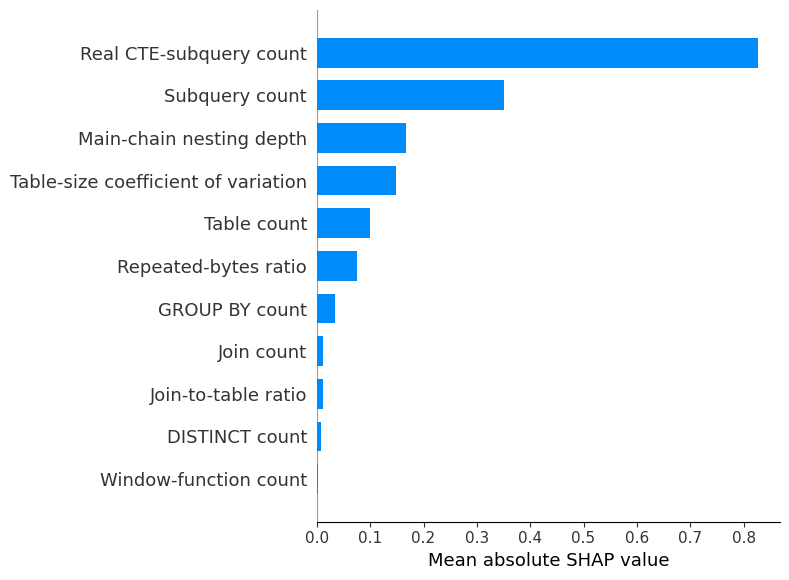

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.ensemble import RandomForestRegressor

# ---------------------------------------------------------
# 1. Entrenar el modelo híbrido final
# ---------------------------------------------------------

X_hybrid = characterization_df[FEATURES_HYBRID].copy()
y_target = characterization_df["complexity_surrogate"].copy()

hybrid_model = RandomForestRegressor(
    n_estimators=500,
    max_depth=8,
    random_state=42,
    n_jobs=-1
)

hybrid_model.fit(X_hybrid, y_target)

# ---------------------------------------------------------
# 2. Calcular valores SHAP
# ---------------------------------------------------------

explainer = shap.TreeExplainer(hybrid_model)
shap_values = explainer.shap_values(X_hybrid)

# Validación para versiones recientes de SHAP
if isinstance(shap_values, list):
    shap_values = shap_values[0]

# ---------------------------------------------------------
# 3. Nombres legibles para el paper
# ---------------------------------------------------------

display_names = {
    "join_count": "Join count",
    "group_by_count": "GROUP BY count",
    "distinct_count": "DISTINCT count",
    "window_count": "Window-function count",
    "subquery_count": "Subquery count",
    "cte_real_subqueries_count": "Real CTE-subquery count",
    "subquery_chain_depth_main": "Main-chain nesting depth",
    "table_count": "Table count",
    "join_to_table_ratio": "Join-to-table ratio",
    "repeated_bytes_ratio": "Repeated-bytes ratio",
    "table_size_cv": "Table-size coefficient of variation"
}

X_display = X_hybrid.rename(columns=display_names)

# ---------------------------------------------------------
# 4. Ranking exacto usado para verificar la figura
# ---------------------------------------------------------

mean_abs_shap = np.abs(shap_values).mean(axis=0)

shap_ranking_df = pd.DataFrame({
    "Feature": [
        display_names.get(feature, feature)
        for feature in FEATURES_HYBRID
    ],
    "Mean_Abs_SHAP": mean_abs_shap
}).sort_values(
    "Mean_Abs_SHAP",
    ascending=False
).reset_index(drop=True)

print("Updated SHAP ranking:")
print(shap_ranking_df)

shap_ranking_df.to_csv(
    "results/shap_ranking.csv",
    index=False
)

# ---------------------------------------------------------
# 5. Figura principal para el paper: SHAP bar plot
# ---------------------------------------------------------

plt.figure()

shap.summary_plot(
    shap_values,
    X_display,
    plot_type="bar",
    max_display=len(FEATURES_HYBRID),
    show=False
)

plt.xlabel("Mean absolute SHAP value")
plt.tight_layout()

# PDF vectorial recomendado para Overleaf
plt.savefig(
    "figures/shap_summary_bar.pdf",
    bbox_inches="tight"
)

# PNG auxiliar de alta resolución
plt.savefig(
    "figures/shap_summary_bar.eps",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()